# TP Jour 4 — Tests d'Hypothèses Statistiques, Segmentation & Restitution BI

### Objectifs de la séance
1. Valider scientifiquement deux hypothèses métier sur votre dataset à l'aide de **tests statistiques adaptés** (`scipy.stats`).
2. Construire une **segmentation / typologie non supervisée (K-Means)** combinant agrégation distribuée **PySpark**, transformation d'asymétrie (`log1p`), standardisation (`StandardScaler`) et labellisation métier vers **`/lakehouse/gold/`**.
3. Développer votre **Dashboard Streamlit interactif** dans `app/dashboard.py` (`http://localhost:8501`) en documentant chaque requête SQL et chaque choix statistique.

**Problématique**

Prédire, au moment de la livraison, la probabilité d’un commentaire écrit après livraison. Le périmètre est celui des commandes livrées à un seul article. La cible vaut 1 si un message est envoyé à partir de la livraison réelle.

**Exécution**

Utiliser le kernel du serveur Jupyter Docker, dans JupyterLab ou depuis VS Code (`Existing Jupyter Server`, `http://localhost:8888/?token=bigdata`). Exécuter toutes les cellules dans l’ordre après J2 et J3.

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from delta.tables import DeltaTable

spark = SparkSession.builder.appName("J4_Stats_Segmentation_Dashboard").getOrCreate()
SILVER_MAIN_PATH = "/lakehouse/silver/olist_commentaires_livraison"
silver_version = DeltaTable.forPath(spark, SILVER_MAIN_PATH).history(1).first().version
silver_j4 = spark.read.format("delta").option("versionAsOf", silver_version).load(SILVER_MAIN_PATH)
silver_j4.createOrReplaceTempView("v_silver_j4")
assert silver_j4.count() > 0
print(f"Silver version {silver_version} — {silver_j4.count():,} commandes disponibles.")

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-bf0d5a67-221b-41d8-aa2b-e5360b37ee8b;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central


	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central


	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 481ms :: artifacts dl 20ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jacks

26/11/19 15:12:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/opt/venv/lib/python3.15/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/19 15:12:08 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/19 15:12:08 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/11/19 15:12:08 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.


26/11/19 15:12:19 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Silver version 7 — 86,835 commandes disponibles.


## 1. Inférence Statistique : Tester vos Hypothèses Métier (`scipy.stats`)

Choisissez **au moins deux tests statistiques** pertinents pour votre sujet parmi :
- **Comparaison de 2 groupes indépendants** sur une variable asymétrique : **Mann-Whitney U** (`stats.mannwhitneyu`).
- **Comparaison de $k \ge 3$ groupes** : **Kruskal-Wallis** (`stats.kruskal`).
- **Lien monotone entre 2 variables quantitatives** non gaussiennes : **Corrélation de rangs de Spearman** (`stats.spearmanr`).
- **Dépendance entre 2 variables qualitatives** : **Test du $\chi^2$** (`stats.chi2_contingency`).

### Exercice 1.1 — Formuler $H_0 / H_1$, projeter les colonnes utiles depuis Silver et conclure
> **Bonne pratique Big Data :** Ne faites jamais `.toPandas()` sur toute une table Silver brute ! Filtrez et sélectionnez (`select(...)`) uniquement les colonnes nécessaires côté PySpark avant de rapatrier les données vers le driver.

**Hypothèses sur les commentaires après livraison**

- **Prix.** H0 : distributions du prix identiques entre commandes avec et sans commentaire. H1 : distributions différentes. Mann-Whitney U convient aux prix asymétriques. La corrélation bisérielle de rang mesure la taille de l’effet.
- **Retard.** H0 : présence du commentaire indépendante de la tranche de retard. H1 : association entre les deux. Le chi-deux porte sur quatre tranches de retard et deux valeurs de la cible ; le V de Cramér mesure l’intensité de l’association.

Le seuil est de 5 %, avec correction de Holm pour deux tests. Les résultats décrivent des associations observées.

In [ ]:
GOLD_TESTS_PATH = "/lakehouse/gold/olist_tests_statistiques"
ALPHA = 0.05
df_sample = silver_j4.select("prix", "a_un_commentaire").dropna().toPandas()
prix_sans = df_sample.loc[df_sample.a_un_commentaire == 0, "prix"].to_numpy()
prix_avec = df_sample.loc[df_sample.a_un_commentaire == 1, "prix"].to_numpy()
assert len(prix_sans) > 0 and len(prix_avec) > 0
mw = stats.mannwhitneyu(prix_avec, prix_sans, alternative="two-sided", method="asymptotic")
effet_prix = 2 * float(mw.statistic) / (len(prix_avec) * len(prix_sans)) - 1

retard_counts = (
    silver_j4.withColumn(
        "retard_groupe",
        F.when(F.col("retard_jours") == 0, 0).when(F.col("retard_jours") <= 3, 1)
        .when(F.col("retard_jours") <= 7, 2).otherwise(3),
    )
    .groupBy("retard_groupe", "a_un_commentaire").count().collect()
)
contingence = np.zeros((4, 2), dtype=np.int64)
for row in retard_counts:
    contingence[row.retard_groupe, row.a_un_commentaire] = row["count"]
chi2, p_chi, ddl, attendus = stats.chi2_contingency(contingence)
assert np.all(attendus >= 5), "Les effectifs attendus du chi-deux doivent être suffisants."
cramer_v = float(np.sqrt(chi2 / contingence.sum()))

# Correction de Holm pour les deux tests.
p_values = np.array([float(mw.pvalue), float(p_chi)])
ordre = np.argsort(p_values)
p_ajustees = np.empty(2)
p_ajustees[ordre] = np.minimum(1, np.maximum.accumulate(p_values[ordre] * np.array([2, 1])))
tests_rows = [
    ("Prix / commentaire", "Mann-Whitney U", len(df_sample), float(mw.statistic), float(mw.pvalue),
     float(p_ajustees[0]), "corrélation bisérielle de rang", effet_prix),
    ("Retard / commentaire", "Chi-deux", int(contingence.sum()), float(chi2), float(p_chi),
     float(p_ajustees[1]), "V de Cramér", cramer_v),
]
tests_df = spark.createDataFrame(
    tests_rows,
    "hypothese string, test string, nb_commandes long, statistique double, p_value double, p_holm double, effet string, valeur_effet double",
).withColumn("decision", F.when(F.col("p_holm") < ALPHA, "Rejet de H0").otherwise("H0 non rejetée"))
tests_df.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_TESTS_PATH)
tests_df.show(truncate=False)
print(f"Prix médian avec commentaire : {np.median(prix_avec):.2f} BRL")
print(f"Prix médian sans commentaire : {np.median(prix_sans):.2f} BRL")
for i, row in enumerate(tests_rows):
    decision = "H0 rejetée" if p_ajustees[i] < ALPHA else "H0 non rejetée"
    print(f"{row[0]} : {decision} après Holm ; p={p_ajustees[i]:.3g} ; {row[6]}={row[7]:.4f}")
print("Une p-value affichée à 0 est inférieure à la précision numérique disponible.")
print("Ces tests mesurent des associations sur le périmètre Silver.")

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


+--------------------+--------------+------------+-----------------+---------------------+---------------------+------------------------------+--------------------+-----------+
|hypothese           |test          |nb_commandes|statistique      |p_value              |p_holm               |effet                         |valeur_effet        |decision   |
+--------------------+--------------+------------+-----------------+---------------------+---------------------+------------------------------+--------------------+-----------+
|Prix / commentaire  |Mann-Whitney U|86835       |8.939540145E8    |1.788304512918315E-12|1.788304512918315E-12|corrélation bisérielle de rang|0.028771414908056236|Rejet de H0|
|Retard / commentaire|Chi-deux      |86835       |2048.144785558572|0.0                  |0.0                  |V de Cramér                   |0.15357938450729353 |Rejet de H0|
+--------------------+--------------+------------+-----------------+---------------------+---------------------+---

## 2. Segmentation / Typologie par Clustering K-Means (`/lakehouse/gold/`)

Quelle que soit la thématique de votre dataset Kaggle, identifiez l'**entité métier pertinente à segmenter** (ex. clients/utilisateurs, stations, zones géographiques, produits, lignes de transport, capteurs...) :
1. **Agrégation PySpark** : résumez chaque entité par **3 à 5 features numériques comportementales** (fréquence, volume, valeur médiane/totale, récence, taux d'incident...).
2. **Prétraitement statistique** : appliquez `np.log1p(...)` sur les features positives asymétriques puis centrez-réduisez avec `StandardScaler()` afin qu'aucune variable à grande échelle n'écrase la distance euclidienne du K-Means.
3. **Interprétation métier** : inspectez les médianes par cluster (`groupby("cluster_id").median()`), attribuez un **nom explicite** à chaque segment (`colonne "segment"`), puis enregistrez la table dans **`/lakehouse/gold/<nom_table_segments>`**.

**Application Olist**

Les catégories de produits d’au moins 100 commandes sont regroupées à partir du prix médian, des frais médians, du délai médian et du taux de retard. Le taux de commentaire est calculé après la segmentation pour interpréter les groupes.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Profils médians des catégories par cluster
            prix_median  frais_medians  delai_median  taux_retard
cluster_id                                                       
0                 80.85         16.185          11.0     0.074215
2                 84.99         17.060           9.0     0.050904
1                188.49         31.225          11.0     0.062587
Prix intermédiaires — délai médian 9 j : 35.9% de commentaires, 19,614 commandes
Prix économiques — délai médian 11 j : 36.0% de commentaires, 64,271 commandes
Prix élevés — délai médian 11 j : 38.5% de commentaires, 2,116 commandes


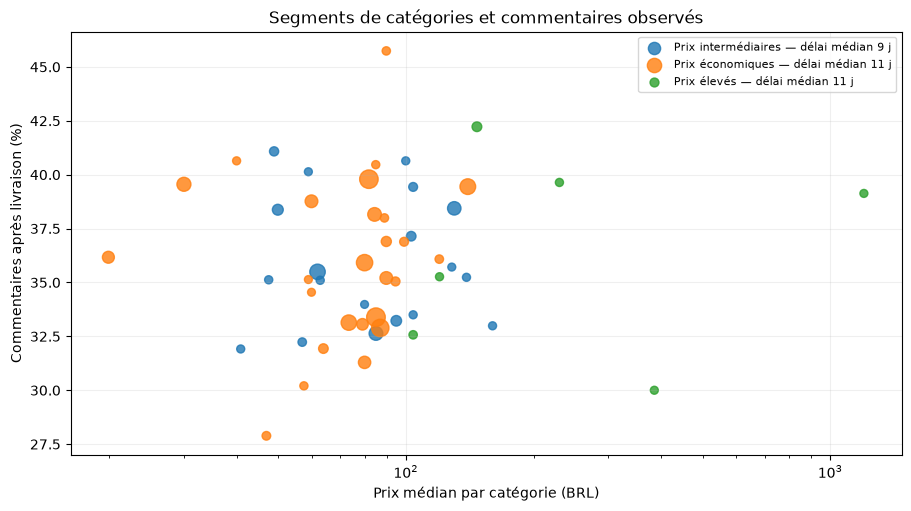

Table de segmentation : /lakehouse/gold/olist_segments_categories (51 catégories).


In [ ]:
import matplotlib.pyplot as plt

GOLD_SEGMENTS_PATH = "/lakehouse/gold/olist_segments_categories"
sql_segments = '''
SELECT categorie_produit, COUNT(*) AS nb_commandes,
       SUM(a_un_commentaire) AS nb_commentaires,
       AVG(CAST(a_un_commentaire AS DOUBLE)) AS taux_commentaire,
       PERCENTILE_APPROX(prix, 0.5, 10000) AS prix_median,
       PERCENTILE_APPROX(frais_livraison, 0.5, 10000) AS frais_medians,
       PERCENTILE_APPROX(delai_livraison_jours, 0.5, 10000) AS delai_median,
       AVG(CAST(livraison_en_retard AS INT)) AS taux_retard
FROM v_silver_j4 GROUP BY categorie_produit
HAVING COUNT(*) >= 100
'''
entities_pd = spark.sql(sql_segments).orderBy("categorie_produit").toPandas()
cluster_features = ["prix_median", "frais_medians", "delai_median", "taux_retard"]
assert len(entities_pd) >= 3 and entities_pd[cluster_features].notna().all().all()
x_clusters = entities_pd[cluster_features].astype(float).copy()
positive_features = ["prix_median", "frais_medians", "delai_median"]
x_clusters[positive_features] = np.log1p(x_clusters[positive_features])
cluster_scaler = StandardScaler()
x_scaled = cluster_scaler.fit_transform(x_clusters)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=20)
entities_pd["cluster_id"] = kmeans.fit_predict(x_scaled)
cluster_medians = entities_pd.groupby("cluster_id")[cluster_features].median().sort_values("prix_median")
segment_names = {
    int(cluster): f"{label} — délai médian {row.delai_median:.0f} j"
    for label, (cluster, row) in zip(
        ["Prix économiques", "Prix intermédiaires", "Prix élevés"], cluster_medians.iterrows()
    )
}
entities_pd["segment"] = entities_pd.cluster_id.map(segment_names)
print("Profils médians des catégories par cluster")
print(cluster_medians.to_string())
for segment, group in entities_pd.groupby("segment"):
    print(f"{segment} : {group.nb_commentaires.sum() / group.nb_commandes.sum():.1%} de commentaires, {group.nb_commandes.sum():,} commandes")

segments_records = [
    (str(row.categorie_produit), int(row.nb_commandes), int(row.nb_commentaires),
     float(row.taux_commentaire), float(row.prix_median), float(row.frais_medians),
     float(row.delai_median), float(row.taux_retard), int(row.cluster_id), str(row.segment))
    for row in entities_pd.itertuples(index=False)
]
segments_df = spark.createDataFrame(
    segments_records,
    "categorie_produit string, nb_commandes long, nb_commentaires long, taux_commentaire double, prix_median double, frais_medians double, delai_median double, taux_retard double, cluster_id int, segment string",
)
segments_df.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_SEGMENTS_PATH)

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for segment, group in entities_pd.groupby("segment"):
    ax.scatter(group.prix_median, 100 * group.taux_commentaire,
               s=30 + 150 * group.nb_commandes / entities_pd.nb_commandes.max(),
               label=segment, alpha=0.8)
ax.set_xlabel("Prix médian par catégorie (BRL)")
ax.set_ylabel("Commentaires après livraison (%)")
ax.set_xscale("log")
ax.set_title("Segments de catégories et commentaires observés")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.show()
print(f"Table de segmentation : {GOLD_SEGMENTS_PATH} ({len(entities_pd)} catégories).")

## 3. Livrable Final : Votre Application `app/dashboard.py` sur Streamlit (`:8501`)

Complétez maintenant **`app/dashboard.py`** pour valoriser vos tables `/lakehouse/gold/` :
- **Architecture respectée** : l'application Streamlit ne doit lire **que** des tables pré-calculées de la couche **Gold** (`/lakehouse/gold/...`), jamais les fichiers CSV bruts !
- **Interactivité** : au moins un filtre utilisateur (`st.selectbox`, `st.multiselect`, `st.slider`) et 3 à 4 visualisations Plotly Express complémentaires.
- **Rigueur explicative** : sous chaque visualisation clé, intégrez un `st.expander("Requête SQL & Justification statistique")` affichant la requête Spark SQL ayant produit la table Gold et justifiant le choix des indicateurs statistiques retenus.

Le dashboard contient les catégories, l’évolution mensuelle, le croisement prix–retard, les segments et les probabilités du modèle. Il lit les tables Gold créées par J3 et J4.

## 4. Prédire la probabilité d’un commentaire après livraison

La régression logistique utilise les 80 % de commandes les plus anciennes pour l’entraînement et réserve les 20 % les plus récentes au test. L’imputation et l’encodage sont appris sur l’entraînement. Les variables incluent le prix, le retard et leur interaction, la catégorie, le poids, les frais et le délai de livraison.

La référence prédit le taux global de l’entraînement. On compare AUC ROC, précision moyenne, Brier et log-loss, puis on regarde la calibration des probabilités. Brier et log-loss diminuent lorsque la qualité probabiliste s’améliore.

L’évaluation reste rétrospective : la durée de suivi varie entre commandes et les commentaires envoyés avant la livraison sont hors de la cible. Un usage réel demande un horizon de réponse commun, par exemple 30 jours, et des étiquettes reconstruites avec ce recul identique.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


+------------------------+-------+------+-------------------+------------------+-------------------+-------------------+------------------+
|modele                  |n_train|n_test|date_coupure       |auc_roc           |average_precision  |brier              |log_loss          |
+------------------------+-------+------+-------------------+------------------+-------------------+-------------------+------------------+
|Régression logistique   |69468  |17367 |2018-06-08 19:33:49|0.5634507504781151|0.4010218809944008 |0.22516912989004084|0.6402564658853916|
|Taux global entraînement|69468  |17367 |2018-06-08 19:33:49|0.5               |0.35515633097253413|0.22906153079653757|0.6506698204592583|
+------------------------+-------+------+-------------------+------------------+-------------------+-------------------+------------------+

Entraînement : 69,468 ; test : 17,367 ; coupure : 2018-06-08 19:33:49


26/11/19 15:12:53 WARN TaskSetManager: Stage 86 contains a task of very large size (1339 KiB). The maximum recommended task size is 1000 KiB.


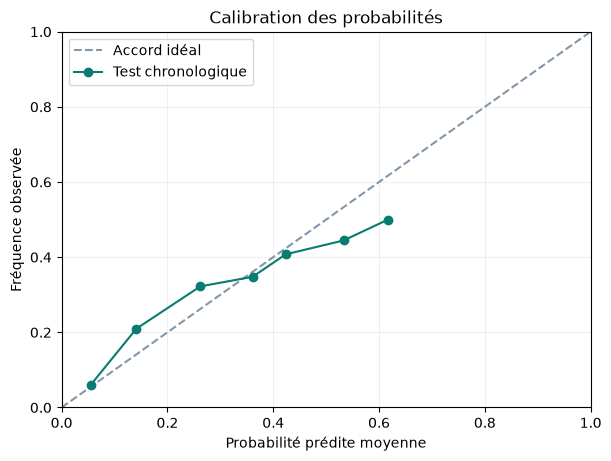

Commande d34b43bca6cc1cb6d49c06d6090770eb : probabilité estimée = 5.4%
Gain de Brier par rapport à la référence : 0.0039


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

GOLD_PREDICTIONS_PATH = "/lakehouse/gold/olist_predictions_commentaires"
GOLD_EVALUATION_PATH = "/lakehouse/gold/olist_modele_evaluation"
GOLD_CALIBRATION_PATH = "/lakehouse/gold/olist_modele_calibration"
model_pd = silver_j4.select(
    "order_id", "date_livraison", "categorie_produit", "prix", "frais_livraison",
    "poids_produit_g", "delai_livraison_jours", "retard_jours", "a_un_commentaire",
).toPandas().sort_values(["date_livraison", "order_id"]).reset_index(drop=True)
assert model_pd.order_id.is_unique

def construire_variables(frame):
    x = frame[["categorie_produit", "delai_livraison_jours"]].copy()
    for column in ["prix", "frais_livraison", "poids_produit_g", "retard_jours"]:
        x[column + "_log"] = np.log1p(frame[column].astype(float))
    x["prix_retard_interaction"] = x["prix_log"] * x["retard_jours_log"]
    return x


date_coupure = model_pd.date_livraison.iloc[int(0.8 * len(model_pd))]
train_mask = model_pd.date_livraison < date_coupure
train_pd, test_pd = model_pd.loc[train_mask], model_pd.loc[~train_mask]
assert len(train_pd) and len(test_pd)
assert train_pd.date_livraison.max() < test_pd.date_livraison.min()
assert train_pd.a_un_commentaire.nunique() == test_pd.a_un_commentaire.nunique() == 2
numeric_features = [
    "delai_livraison_jours", "prix_log", "frais_livraison_log", "poids_produit_g_log",
    "retard_jours_log", "prix_retard_interaction",
]
preprocessing = ColumnTransformer([
    ("numerique", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler()),
    ]), numeric_features),
    ("categorie", OneHotEncoder(handle_unknown="ignore"), ["categorie_produit"]),
])
modele_commentaire = Pipeline([
    ("preparation", preprocessing),
    ("regression_logistique", LogisticRegression(max_iter=2000, random_state=42)),
])
x_train, x_test = construire_variables(train_pd), construire_variables(test_pd)
y_train = train_pd.a_un_commentaire.astype(int).to_numpy()
y_test = test_pd.a_un_commentaire.astype(int).to_numpy()
modele_commentaire.fit(x_train, y_train)
probabilites_test = modele_commentaire.predict_proba(x_test)[:, 1]
probabilites_reference = np.full(len(test_pd), y_train.mean())
evaluation_rows = []
for name, probabilities in [
    ("Régression logistique", probabilites_test),
    ("Taux global entraînement", probabilites_reference),
]:
    evaluation_rows.append((
        name, len(train_pd), len(test_pd), str(date_coupure),
        float(roc_auc_score(y_test, probabilities)), float(average_precision_score(y_test, probabilities)),
        float(brier_score_loss(y_test, probabilities)), float(log_loss(y_test, probabilities)),
    ))
evaluation_df = spark.createDataFrame(
    evaluation_rows,
    "modele string, n_train long, n_test long, date_coupure string, auc_roc double, average_precision double, brier double, log_loss double",
)
evaluation_df.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_EVALUATION_PATH)
evaluation_df.show(truncate=False)
print(f"Entraînement : {len(train_pd):,} ; test : {len(test_pd):,} ; coupure : {date_coupure}")

prediction_rows = [
    (str(row.order_id), str(row.categorie_produit), float(row.prix), int(row.retard_jours),
     int(row.a_un_commentaire), float(probability))
    for row, probability in zip(test_pd.itertuples(index=False), probabilites_test)
]
predictions_df = spark.createDataFrame(
    prediction_rows,
    "order_id string, categorie_produit string, prix double, retard_jours int, a_un_commentaire int, probabilite_commentaire double",
)
predictions_df.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_PREDICTIONS_PATH)
calibration_df = (
    predictions_df.withColumn("groupe_probabilite", F.least(F.floor(F.col("probabilite_commentaire") * 10), F.lit(9)).cast("int"))
    .groupBy("groupe_probabilite")
    .agg(F.count("*").alias("nb_commandes"), F.avg("probabilite_commentaire").alias("probabilite_moyenne"),
         F.avg("a_un_commentaire").alias("frequence_observee"))
)
calibration_df.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_CALIBRATION_PATH)
calibration_rows = calibration_df.orderBy("groupe_probabilite").collect()
fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
ax.plot([0, 1], [0, 1], "--", color="#8297aa", label="Accord idéal")
ax.plot([r.probabilite_moyenne for r in calibration_rows], [r.frequence_observee for r in calibration_rows],
        "o-", color="#087c70", label="Test chronologique")
ax.set(xlabel="Probabilité prédite moyenne", ylabel="Fréquence observée", title="Calibration des probabilités")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

exemple = test_pd.head(1)
probabilite_exemple = float(modele_commentaire.predict_proba(construire_variables(exemple))[0, 1])
print(f"Commande {exemple.iloc[0].order_id} : probabilité estimée = {probabilite_exemple:.1%}")
print(f"Gain de Brier par rapport à la référence : {evaluation_rows[1][6] - evaluation_rows[0][6]:.4f}")

In [ ]:
gold_expected = {
    "olist_commentaires_categories", "olist_commentaires_mensuels", "olist_commentaires_prix_retard",
    "olist_segments_categories", "olist_tests_statistiques",
    "olist_predictions_commentaires", "olist_modele_evaluation", "olist_modele_calibration",
}
fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = spark._jvm.org.apache.hadoop.fs.Path
gold_tables = {
    s.getPath().getName() for s in fs.listStatus(PathHDFS("/lakehouse/gold"))
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log"))
}
assert gold_expected.issubset(gold_tables), f"Tables manquantes : {sorted(gold_expected - gold_tables)}"
for name in sorted(gold_expected):
    print(f"{name} : {spark.read.format('delta').load('/lakehouse/gold/' + name).count():,} lignes")
print("Dashboard : http://localhost:8501")

olist_commentaires_categories : 74 lignes


olist_commentaires_mensuels : 25 lignes


olist_commentaires_prix_retard : 20 lignes


olist_modele_calibration : 7 lignes


olist_modele_evaluation : 2 lignes


olist_predictions_commentaires : 17,367 lignes


olist_segments_categories : 51 lignes


olist_tests_statistiques : 2 lignes
Dashboard : http://localhost:8501
